# Small CNN
Small CNN trained on 128x128 aspect-ratio-preserving padded RGB inputs.
Loads the frozen split from `data/splits/patient_split.csv`.

Preprocessing (`load_and_pad`) comes from the shared `src/preprocessing.py` module, so this
notebook, the baseline, and ResNet-18 all preprocess images identically.

In [1]:
import sys
sys.path.append("..")

import kagglehub
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from torch import nn
from torch.utils.data import Dataset, DataLoader

from src.preprocessing import load_and_pad

IMG_SIZE = 128
SEED = 42
torch.manual_seed(SEED)

# Prefer a GPU: CUDA on other platforms, MPS (Metal) on Apple Silicon, else fall back to CPU.
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Using device:", device)

Using device: mps


## Load the frozen split and build a Dataset/DataLoader
Images are loaded lazily per-batch.

In [2]:
manifest = pd.read_csv("../data/splits/patient_split.csv")
print(manifest["split"].value_counts())

# The manifest only stores filename + category, not an absolute path (those differ per machine).
# The path is rebuild the same way as 00_eda.ipynb (<kagglehub download root>/<category>/<filename>) 
download_path = Path(kagglehub.dataset_download("iarunava/cell-images-for-detecting-malaria"))
data_dir = download_path / "cell_images"
if (data_dir / "cell_images").exists():
    data_dir = data_dir / "cell_images"

CLASS_TO_IDX = {"Uninfected": 0, "Parasitized": 1}


class CellDataset(Dataset):
    def __init__(self, df: pd.DataFrame, data_dir: Path):
        self.df = df.reset_index(drop=True)
        self.data_dir = data_dir

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        path = self.data_dir / row["category"] / row["filename"]

        # load_and_pad (src/preprocessing.py) returns (height, width, channels) in [0, 1];
        # rearrange to (channels, height, width), since PyTorch's conv layers expect channels first.
        img = load_and_pad(str(path), IMG_SIZE)
        img = torch.from_numpy(img).permute(2, 0, 1)

        label = CLASS_TO_IDX[row["category"]]
        return img, label


train_ds = CellDataset(manifest[manifest["split"] == "train"], data_dir)
val_ds = CellDataset(manifest[manifest["split"] == "val"], data_dir)
test_ds = CellDataset(manifest[manifest["split"] == "test"], data_dir)

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

split
train    19124
val       4324
test      4110
Name: count, dtype: int64


## Small CNN

In [3]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes: int = 2):
        super().__init__()
        
        # Conv2d(in_channels, out_channels, kernel_size, padding): in_channels must match the
        # previous layer's out_channels (3 for the RGB input); padding=1 with a 3x3 kernel keeps
        # the spatial size unchanged, so only MaxPool2d(2) halves it (128 -> 64 -> 32 -> 16).
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 128 -> 64
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 64 -> 32
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 32 -> 16
        )

        # AdaptiveAvgPool2d(1) collapses each of the 64 channels' 16x16 feature map down to a
        # single number (its average), giving a (64, 1, 1) output regardless of input resolution.
        # This replaces a Flatten + Linear(64*16*16, 128), which would need 2.1M parameters
        # (almost the entire model) just to compress the flattened map down to 128 values -
        # pooling does that compression for free, with no learned weights at all, leaving only
        # a small Linear(64, num_classes) to learn.
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = SmallCNN().to(device)
# Cross Entropy Loss = Binary Cross-Entropy as the classification is binary
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

## Training loop (validation only - freeze the protocol before touching test_loader)

In [4]:
from sklearn.metrics import (
    f1_score, roc_auc_score, roc_curve, confusion_matrix,
    precision_score, recall_score, precision_recall_curve,
)


def run_epoch(loader, train: bool):
    model.train(mode=train)
    total_loss, correct, n = 0.0, 0, 0
    all_labels, all_preds, all_probs = [], [], []

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        if train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(train):
            outputs = model(images)
            loss = criterion(outputs, labels)
            if train:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        n += images.size(0)

        # softmax turns the 2 raw logits (scores from model e.g. (1.2, -0.3)) into class 
        # probabilities that sum to 1; we keep index 1 (probability of "Parasitized") for 
        # ROC-AUC, which needs probabilities rather than hard 0/1 predictions.
        probs = torch.softmax(outputs, dim=1)[:, 1]
        all_labels.extend(labels.cpu().tolist())
        all_preds.extend(preds.cpu().tolist())
        all_probs.extend(probs.detach().cpu().tolist())

    # Every metric below is computed once over the whole epoch's predictions, not averaged
    # per batch - a single batch's TP/FP/FN counts are too small and skewed on their own.
    # precision/recall/f1 here are measured at the default 0.5 decision threshold (argmax).
    precision = precision_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    roc_auc = roc_auc_score(all_labels, all_probs)
    cm = confusion_matrix(all_labels, all_preds)
    # fpr/tpr and pr_precision/pr_recall sweep every possible threshold, for the ROC and
    # precision-recall curves below - distinct from the single-threshold scores above.
    fpr, tpr, _ = roc_curve(all_labels, all_probs)
    pr_precision, pr_recall, _ = precision_recall_curve(all_labels, all_probs)

    return {
        "loss": total_loss / n,
        "acc": correct / n,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc,
        "cm": cm,
        "fpr": fpr,
        "tpr": tpr,
        "pr_precision": pr_precision,
        "pr_recall": pr_recall,
    }


# NUM_EPOCHS is now just an upper bound - early stopping (below) decides the actual run length.
NUM_EPOCHS = 20
# Early stopping: stop once val_loss hasn't improved by at least MIN_DELTA (relative) for
# PATIENCE consecutive epochs. This is what catches the "7th to 10th epoch barely helped"
# situation - it keeps training past a single noisy/flat epoch (patience), but cuts the run
# once the trend itself has genuinely plateaued, instead of us eyeballing the printed numbers.
PATIENCE = 2
MIN_DELTA = 0.01  # require >= 1% relative improvement in val_loss to count as progress

history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": [],
    "train_precision": [], "val_precision": [],
    "train_recall": [], "val_recall": [],
    "train_f1": [], "val_f1": [],
    "train_auc": [], "val_auc": [],
}

best_val_loss = None
epochs_without_improvement = 0

for epoch in range(1, NUM_EPOCHS + 1):
    train_metrics = run_epoch(train_loader, train=True)
    val_metrics = run_epoch(val_loader, train=False)

    for key in ("loss", "acc", "precision", "recall", "f1"):
        history[f"train_{key}"].append(train_metrics[key])
        history[f"val_{key}"].append(val_metrics[key])
    history["train_auc"].append(train_metrics["roc_auc"])
    history["val_auc"].append(val_metrics["roc_auc"])

    print(f"Epoch {epoch}: "
          f"train_loss={train_metrics['loss']:.4f} train_acc={train_metrics['acc']:.4f} "
          f"train_precision={train_metrics['precision']:.4f} train_recall={train_metrics['recall']:.4f} "
          f"train_f1={train_metrics['f1']:.4f} train_auc={train_metrics['roc_auc']:.4f} | "
          f"val_loss={val_metrics['loss']:.4f} val_acc={val_metrics['acc']:.4f} "
          f"val_precision={val_metrics['precision']:.4f} val_recall={val_metrics['recall']:.4f} "
          f"val_f1={val_metrics['f1']:.4f} val_auc={val_metrics['roc_auc']:.4f}")
    print("val confusion matrix:\n", val_metrics["cm"])

    # First epoch always "improves" (nothing to compare against yet).
    if best_val_loss is None:
        best_val_loss = val_metrics["loss"]
    else:
        relative_improvement = (best_val_loss - val_metrics["loss"]) / best_val_loss
        if relative_improvement >= MIN_DELTA:
            best_val_loss = val_metrics["loss"]
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                print(f"Early stopping at epoch {epoch}: val_loss improved by less than "
                      f"{MIN_DELTA:.0%} for {PATIENCE} consecutive epochs.")
                break

# Keep the final epoch's val metrics around for the ROC/PR curve plots below.
final_val_metrics = val_metrics

Epoch 1: train_loss=0.6599 train_acc=0.6001 train_precision=0.6079 train_recall=0.5609 train_f1=0.5834 train_auc=0.6497 | val_loss=0.6681 val_acc=0.6383 val_precision=0.6225 val_recall=0.7853 val_f1=0.6945 val_auc=0.6996
val confusion matrix:
 [[ 982 1078]
 [ 486 1778]]


Epoch 2: train_loss=0.5878 train_acc=0.7441 train_precision=0.8294 train_recall=0.6136 train_f1=0.7054 train_auc=0.8282 | val_loss=0.5396 val_acc=0.7738 val_precision=0.9465 val_recall=0.6020 val_f1=0.7360 val_auc=0.9312
val confusion matrix:
 [[1983   77]
 [ 901 1363]]


Epoch 3: train_loss=0.4097 train_acc=0.8717 train_precision=0.9684 train_recall=0.7680 train_f1=0.8567 train_auc=0.9260 | val_loss=0.4142 val_acc=0.8839 val_precision=0.9726 val_recall=0.8008 val_f1=0.8784 val_auc=0.9494
val confusion matrix:
 [[2009   51]
 [ 451 1813]]


Epoch 4: train_loss=0.3485 train_acc=0.8925 train_precision=0.9796 train_recall=0.8013 train_f1=0.8816 train_auc=0.9418 | val_loss=0.3902 val_acc=0.8925 val_precision=0.9757 val_recall=0.8149 val_f1=0.8881 val_auc=0.9528
val confusion matrix:
 [[2014   46]
 [ 419 1845]]


Epoch 5: train_loss=0.3213 train_acc=0.8989 train_precision=0.9810 train_recall=0.8132 train_f1=0.8892 train_auc=0.9453 | val_loss=0.3972 val_acc=0.9080 val_precision=0.9760 val_recall=0.8450 val_f1=0.9058 val_auc=0.9590
val confusion matrix:
 [[2013   47]
 [ 351 1913]]


...

Epoch 11: train_loss=0.1814 train_acc=0.9379 train_precision=0.9742 train_recall=0.8995 train_f1=0.9354 train_auc=0.9810 | val_loss=0.2159 val_acc=0.9246 val_precision=0.9579 val_recall=0.8953 val_f1=0.9256 val_auc=0.9749
val confusion matrix:
 [[1971   89]
 [ 237 2027]]


Epoch 12: train_loss=0.1701 train_acc=0.9440 train_precision=0.9760 train_recall=0.9103 train_f1=0.9420 train_auc=0.9823 | val_loss=0.2129 val_acc=0.9292 val_precision=0.9680 val_recall=0.8944 val_f1=0.9298 val_auc=0.9768
val confusion matrix:
 [[1993   67]
 [ 239 2025]]


Epoch 13: train_loss=0.1653 train_acc=0.9451 train_precision=0.9765 train_recall=0.9120 train_f1=0.9431 train_auc=0.9829 | val_loss=0.1991 val_acc=0.9352 val_precision=0.9737 val_recall=0.9006 val_f1=0.9358 val_auc=0.9781
val confusion matrix:
 [[2005   55]
 [ 225 2039]]


Epoch 14: train_loss=0.1601 train_acc=0.9459 train_precision=0.9752 train_recall=0.9150 train_f1=0.9441 train_auc=0.9843 | val_loss=0.1987 val_acc=0.9339 val_precision=0.9750 val_recall=0.8966 val_f1=0.9342 val_auc=0.9773
val confusion matrix:
 [[2008   52]
 [ 234 2030]]


Epoch 15: train_loss=0.1659 train_acc=0.9445 train_precision=0.9752 train_recall=0.9120 train_f1=0.9426 train_auc=0.9831 | val_loss=0.2130 val_acc=0.9341 val_precision=0.9613 val_recall=0.9108 val_f1=0.9354 val_auc=0.9774
val confusion matrix:
 [[1977   83]
 [ 202 2062]]
Early stopping at epoch 15: val_loss improved by less than 1% for 2 consecutive epochs.


## Learning curves
Train vs. validation loss and accuracy across epochs - the proposal's "record learning curves" check.
A widening gap (train still improving, val flat/worsening) signals overfitting.

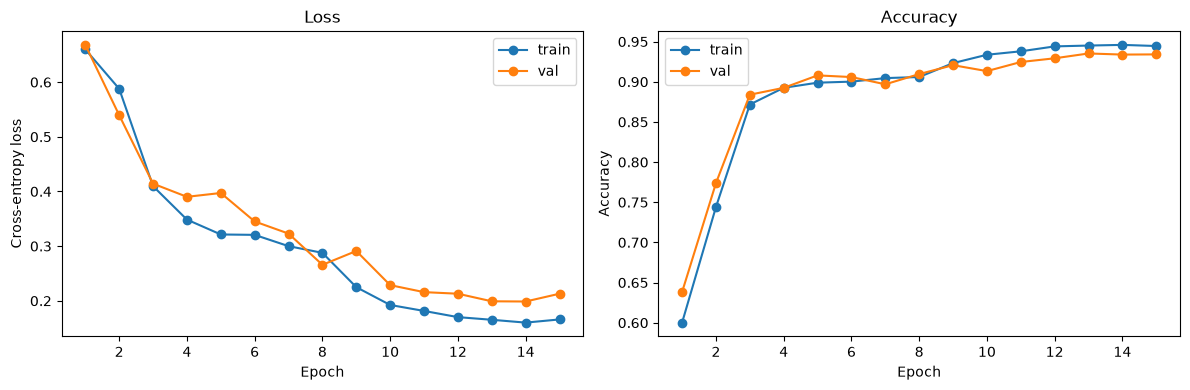

In [5]:
import matplotlib.pyplot as plt

# Use the actual number of epochs that ran, not NUM_EPOCHS - early stopping may have cut it short.
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, history["train_loss"], marker="o", label="train")
axes[0].plot(epochs_range, history["val_loss"], marker="o", label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(epochs_range, history["train_acc"], marker="o", label="train")
axes[1].plot(epochs_range, history["val_acc"], marker="o", label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

## Confusion matrix (final epoch, validation set)
Same style as Shania's Grad-CAM notebook, so the plots look consistent across the project.
Percentages are row-normalized (share of each true class), matching `CLASS_TO_IDX`'s ordering
(`0 = Uninfected, 1 = Parasitized`) for both axes.

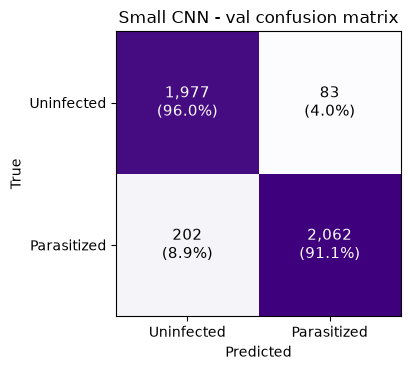

In [6]:
cm = final_val_metrics["cm"]
class_names = ["Uninfected", "Parasitized"]

fig, ax = plt.subplots(figsize=(4.2, 3.8))
ax.imshow(cm, cmap="Purples")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
ax.set_xticks([0, 1], class_names)
ax.set_yticks([0, 1], class_names)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Small CNN - val confusion matrix")
plt.tight_layout()
plt.show()

## ROC curve (final epoch, validation set)
The dashed diagonal is the random-guess baseline (AUC = 0.5): a model with no real discriminative
power would produce a ROC curve that tracks this line on average. The further the actual curve
bows toward the top-left corner (high true-positive rate at a low false-positive rate), the better
the model is than chance.

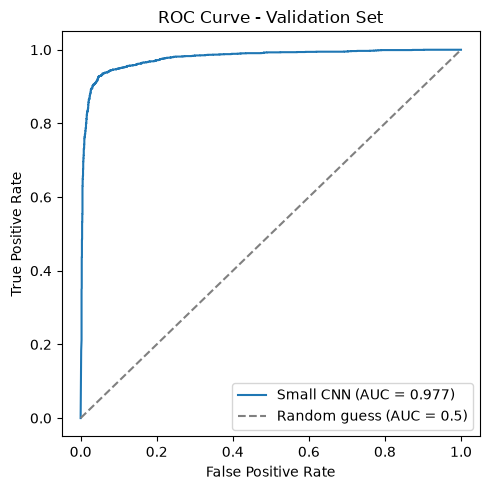

In [7]:
plt.figure(figsize=(5, 5))
plt.plot(final_val_metrics["fpr"], final_val_metrics["tpr"],
         label=f"Small CNN (AUC = {final_val_metrics['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess (AUC = 0.5)")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Validation Set")
plt.legend()
plt.tight_layout()
plt.show()

## Precision-Recall curve (final epoch, validation set)
The dashed horizontal line is the random-guess baseline: a classifier with no real
discriminative power would have precision roughly equal to the positive class's share of
the validation set, regardless of recall. A curve staying above that line, especially as
recall approaches 1, means the model ranks true positives ahead of negatives better than chance.

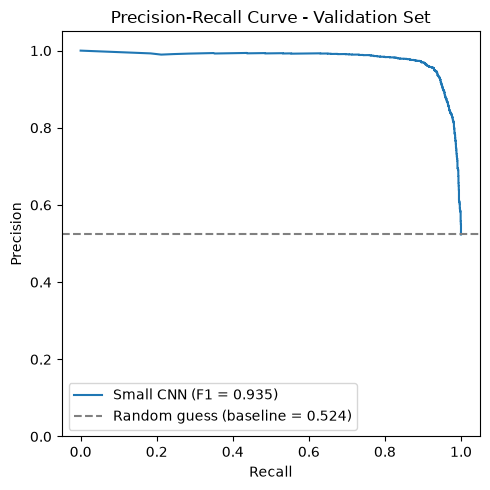

In [8]:
plt.figure(figsize=(5, 5))
plt.plot(final_val_metrics["pr_recall"], final_val_metrics["pr_precision"],
         label=f"Small CNN (F1 = {final_val_metrics['f1']:.3f})")

# Baseline: the positive class's prevalence in the validation set (what a random classifier's
# precision would hover around, regardless of threshold/recall).
baseline = (val_ds.df["category"] == "Parasitized").mean()
plt.axhline(baseline, linestyle="--", color="gray", label=f"Random guess (baseline = {baseline:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Validation Set")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

## Save the trained model
Writes the trained weights (plus the bits needed to use them later: image size, class index
mapping) to `models/cnn.pt`, so Shania can load this model for Grad-CAM without retraining it.

In [9]:
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "cnn.pt"

# Load with: checkpoint = torch.load(MODEL_PATH, map_location=device, weights_only=False)
#            model = SmallCNN(); model.load_state_dict(checkpoint["model_state_dict"])
#            preprocess with: load_and_pad(path, checkpoint["img_size"])  (already [0, 1], no
#            further normalization needed - that's what normalize_method="zero_one" means)
torch.save({
    "model_state_dict": model.state_dict(),
    "class_to_idx": CLASS_TO_IDX,
    "img_size": IMG_SIZE,
    "normalize_method": "zero_one",
    "val_metrics": {k: v for k, v in final_val_metrics.items() if k not in ("fpr", "tpr", "pr_precision", "pr_recall")},
}, MODEL_PATH)

print(f"Saved trained Small CNN to {MODEL_PATH}")

Saved trained Small CNN to ../models/cnn.pt
